# Words and phrases in primary cs.AI versus cs.LG abstracts

Compare January 2025–October 2026 abstracts from the collected cs.AI-tagged corpus. Each paper belongs to one group according to its **primary** category. Primary cs.LG papers here are also tagged cs.AI; this is not all machine-learning research on arXiv.

Primary cs.AI is randomly undersampled to match the cs.LG group using a fixed seed. Selected plural forms are merged with an explicit mapping. The full selected dataset and raw text remain available.

Questions: Which terms are more prevalent in either group? Which are common to both? What do example abstracts suggest those terms mean?

This pools the selected period; it does not test a before/after shift or explain its cause. Different time composition, subfields, and writing styles can affect language differences. No TF-IDF, clustering, statistical significance tests, or automated topic labels yet.

Run cells yourself. No API calls or file writes; original titles and abstracts are preserved. Dependencies are the same as the descriptive notebook: pandas, Seaborn, Matplotlib, and IPython/Jupyter. Counting uses Python's standard library.


In [ ]:
from collections import Counter
from pathlib import Path
import hashlib
import json
import platform
import re
import sys

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

project_root = Path.cwd()
if not (project_root / "arxiv_collection.py").is_file():
    project_root = project_root.parent
if not (project_root / "arxiv_collection.py").is_file():
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from arxiv_collection import month_ranges

RUN_ID = "2026-11-12_cs-ai"
DATA_DIR = project_root / "data" / "raw" / "arxiv_cs_ai_2022_2026"
START = "2025-01-01"
END = "2026-10-31"  # Inclusive UTC date.
GROUPS = ["cs.AI", "cs.LG"]
MIN_DOCS = 20  # Minimum abstracts containing a term across both groups combined.
TOP_N = 15
SAMPLE_SEED = 42
PINK, PURPLE, GREEN = "#D96A9B", "#7352A2", "#39866A"
sns.set_theme(style="whitegrid", palette=[PURPLE, PINK, GREEN], rc={
    "axes.facecolor": "#FCF9FC", "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
print({"Python": platform.python_version(), "pandas": pd.__version__, "seaborn": sns.__version__})


## 1. Load the selected months and inspect the two groups

Check saved-month settings, hashes, and counts. Invalid dates, duplicate IDs, missing abstracts, or unexpected scope stop the notebook rather than silently dropping records. Other primary categories are intentionally outside this comparison and their counts are shown.


In [2]:
run = json.loads((project_root / "collection_runs" / f"{RUN_ID}.json").read_text(encoding="utf-8"))
start_bound = pd.Timestamp(START, tz="UTC")
end_exclusive = pd.Timestamp(END, tz="UTC") + pd.Timedelta(days=1)
if run["retrieval_finished"] is None:
    raise RuntimeError("The source collection is not recorded as complete.")
if start_bound < pd.Timestamp(run["submission_start"]) or end_exclusive > pd.Timestamp(run["submission_end"]) + pd.Timedelta(seconds=1):
    raise ValueError("Selected dates fall outside the collection's submission range.")
windows = month_ranges(start_bound.strftime("%Y-%m"), pd.Timestamp(END).strftime("%Y-%m"))
records = []
for start_date, end_date in windows:
    stem = f"{start_date}_{end_date}"
    manifest = json.loads((DATA_DIR / f"{stem}.manifest.json").read_text(encoding="utf-8"))
    expected = {"categories": run["categories"], "start_date": start_date, "end_date": end_date}
    if manifest["status"] != "complete" or manifest["settings"] != expected:
        raise RuntimeError(f"Unexpected checkpoint settings for {stem}.")
    payload = (DATA_DIR / manifest["data_file"]).read_bytes()
    if hashlib.sha256(payload).hexdigest() != manifest["sha256"]:
        raise RuntimeError(f"Data hash mismatch for {stem}.")
    monthly_records = [json.loads(line) for line in payload.decode("utf-8").splitlines()]
    if len(monthly_records) != manifest["api_total"] or len(monthly_records) != manifest["retrieved_count"]:
        raise RuntimeError(f"Saved count mismatch for {stem}.")
    records.extend(monthly_records)

source = pd.DataFrame(records)
del records, monthly_records, payload
source["submitted"] = pd.to_datetime(source["submitted_at"], utc=True, errors="coerce", format="ISO8601")
if source["submitted"].isna().any():
    raise RuntimeError("Invalid submission dates need review.")
if not source["arxiv_id"].map(lambda value: isinstance(value, str) and bool(value.strip())).all():
    raise RuntimeError("Missing or invalid IDs need review.")
if source["arxiv_id"].str.replace(r"v\d+$", "", regex=True).duplicated().any():
    raise RuntimeError("Duplicate paper IDs need review.")
if not source["categories"].map(lambda values: isinstance(values, list) and "cs.AI" in values).all():
    raise RuntimeError("Unexpected records without a cs.AI tag.")

in_period = source["submitted"].ge(start_bound) & source["submitted"].lt(end_exclusive)
period = source.loc[in_period].copy()
print("Records in the selected period, before primary-category selection:", len(period))
display(period["primary_category"].value_counts().to_frame("papers"))
papers_full = period.loc[period["primary_category"].isin(GROUPS)].copy()
if not papers_full["abstract"].map(lambda value: isinstance(value, str) and bool(value.strip())).all():
    raise RuntimeError("Missing or blank abstracts need review; none have been excluded automatically.")
group_sizes_full = papers_full.groupby("primary_category").size().reindex(GROUPS, fill_value=0)
if group_sizes_full.eq(0).any():
    raise RuntimeError("Both groups must contain papers.")
print("Records before undersampling:", len(papers_full))
print("Excluded other primary categories:", len(period) - len(papers_full))
display(group_sizes_full.to_frame("available_abstracts"))
display(pd.crosstab(papers_full["submitted"].dt.year, papers_full["primary_category"]).reindex(columns=GROUPS, fill_value=0))


Records in the selected period, before primary-category selection: 98851


,papers
primary_category,
cs.AI,25810
cs.LG,19602
cs.CL,12922
cs.CV,12914
cs.CR,3698
...,...
math.RA,1
q-bio.CB,1
physics.space-ph,1


Records before undersampling: 45412
Excluded other primary categories: 53439


,available_abstracts
primary_category,
cs.AI,25810
cs.LG,19602


primary_category,cs.AI,cs.LG
submitted,,
2025,8461,9774
2026,17349,9828


### Balance the groups

Keep all primary cs.LG papers and randomly sample the same number of primary cs.AI papers **without replacement**. Sorting by arXiv ID before sampling makes the fixed-seed selection reproducible for the same data and software environment. Change `SAMPLE_SEED` to explore sensitivity later.

`papers_full` retains the full comparison pool. `papers` is the balanced sample used by every term table, plot, and example below. Counts and percentages are recalculated after sampling. The notebook stops if cs.AI is smaller rather than silently sampling the other group.

Equal sizes do not balance submission dates or topics, remove corpus-selection effects, or establish statistical significance. Review the before/after counts and yearly composition. A single sample can change the rankings; conclusions need researcher review.


In [3]:
ai_pool = papers_full.loc[papers_full["primary_category"].eq("cs.AI")].sort_values("arxiv_id")
lg_pool = papers_full.loc[papers_full["primary_category"].eq("cs.LG")].sort_values("arxiv_id")
if len(ai_pool) < len(lg_pool):
    raise ValueError("cs.AI has fewer abstracts than cs.LG. Review the sampling decision before proceeding.")

ai_sample = ai_pool.sample(n=len(lg_pool), replace=False, random_state=SAMPLE_SEED)
papers = pd.concat([ai_sample, lg_pool], ignore_index=True).sort_values(
    ["submitted", "arxiv_id"]
).reset_index(drop=True)
group_sizes = papers.groupby("primary_category").size().reindex(GROUPS, fill_value=0)
assert group_sizes["cs.AI"] == group_sizes["cs.LG"]
assert not papers["arxiv_id"].duplicated().any()

sampling_summary = pd.DataFrame({"available": group_sizes_full, "used": group_sizes})
sampling_summary["not_selected"] = sampling_summary["available"] - sampling_summary["used"]
print("Random seed:", SAMPLE_SEED)
display(sampling_summary)
print("Yearly composition after sampling (2026 covers January–October):")
display(pd.crosstab(papers["submitted"].dt.year, papers["primary_category"]).reindex(columns=GROUPS, fill_value=0))
# Inspect these IDs if needed; nothing is written to disk.
sampled_ai_ids = ai_sample["arxiv_id"].tolist()


Random seed: 42


,available,used,not_selected
primary_category,,,
cs.AI,25810,19602,6208
cs.LG,19602,19602,0


Yearly composition after sampling (2026 covers January–October):


primary_category,cs.AI,cs.LG
submitted,,
2025,6446,9774
2026,13156,9828


## 2. Visible text-handling rules

- Lowercase abstracts; preserve raw text in `papers`.
- Match ASCII letters/digits with internal hyphens, keeping terms such as `gpt-4`, `llms`, and `3d`; ignore numbers without letters.
- Remove the explicit common-English stop words below. Research words such as `model`, `learning`, `paper`, and `method` are **not** removed.
- Count single words and adjacent two-word phrases separately. Build phrases from original token order: removing `of` from `model of learning` does not create `model learning`.
- Do not join phrases across sentence-like punctuation (`. ! ? ; :`). Soft line breaks count as whitespace. This is a simple rule, not a linguistic sentence parser.
- Merge only the plural forms listed in `PLURAL_MAP`, before counting words and phrases: `models` and `model` both become `model`, including in phrases such as `language models`. Do not strip every trailing `s`: words such as `analysis`, `loss`, and `bias` remain unchanged.
- No other stemming, synonym merging, or acronym expansion. Unlisted plurals remain separate. Formula/LaTeX fragments may appear and need inspection.
- Count each term once per abstract, regardless of repetitions.

Changing these rules changes the results. Inspect them before interpreting the tables.


In [4]:
STOP_WORDS = set("""
a an and are as at be been being but by can could did do does doing down during
each few for from further had has have having he her here hers herself him himself
his how i if in into is it its itself just me more most my myself no nor not of
off on once only or other ought our ours ourselves out over own same she should
so some such than that the their theirs them themselves then there these they
this those through to too under until up us very was we were what when where
which while who whom why will with would you your yours yourself yourselves
also both any all about above after again against am because before below
between cannot without within across via may might must shall whether
""".split())
# Conservative, editable mapping: review additions before changing the analysis.
PLURAL_MAP = {
    "models": "model", "agents": "agent", "methods": "method",
    "systems": "system", "tasks": "task", "datasets": "dataset",
    "networks": "network", "frameworks": "framework",
}
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")
SENTENCE_BREAKS = re.compile(r"[.!?;:]+")

def abstract_terms(text):
    """Return the distinct words and adjacent two-word phrases in one abstract."""
    terms = set()
    for segment in SENTENCE_BREAKS.split(text.lower()):
        tokens = [PLURAL_MAP.get(token, token) for token in TOKEN_PATTERN.findall(segment)]
        keep = [token not in STOP_WORDS and any("a" <= char <= "z" for char in token) for token in tokens]
        terms.update(token for token, wanted in zip(tokens, keep) if wanted)
        terms.update(
            first + " " + second
            for first, second, first_ok, second_ok in zip(tokens, tokens[1:], keep, keep[1:])
            if first_ok and second_ok
        )
    return terms

print("Plural mapping:", PLURAL_MAP)
print("Stop words:", ", ".join(sorted(STOP_WORDS)))
print("Example input: Model of learning. GPT-4 models learn from 3D data.")
print("Example terms:", sorted(abstract_terms("Model of learning. GPT-4 models learn from 3D data.")))


Plural mapping: {'models': 'model', 'agents': 'agent', 'methods': 'method', 'systems': 'system', 'tasks': 'task', 'datasets': 'dataset', 'networks': 'network', 'frameworks': 'framework'}
Stop words: a, about, above, across, after, again, against, all, also, am, an, and, any, are, as, at, be, because, been, before, being, below, between, both, but, by, can, cannot, could, did, do, does, doing, down, during, each, few, for, from, further, had, has, have, having, he, her, here, hers, herself, him, himself, his, how, i, if, in, into, is, it, its, itself, just, may, me, might, more, most, must, my, myself, no, nor, not, of, off, on, once, only, or, other, ought, our, ours, ourselves, out, over, own, same, shall, she, should, so, some, such, than, that, the, their, theirs, them, themselves, then, there, these, they, this, those, through, to, too, under, until, up, us, very, via, was, we, were, what, when, where, whether, which, while, who, whom, why, will, with, within, without, would, you, 

## 3. Count abstracts containing each term

The counters store document counts from the balanced sample, not total token counts. A singular and its mapped plural in the same abstract count once for the normalized term. Terms are processed one abstract at a time rather than storing a large document-by-term matrix. This may take a little time; progress is printed every 10,000 abstracts.

For every retained term:

- `ai_pct = 100 × ai_docs / number of primary cs.AI abstracts`
- `lg_pct = 100 × lg_docs / number of primary cs.LG abstracts`
- `ai_minus_lg_pp = ai_pct − lg_pct`, in **percentage points**.

Positive differences indicate greater prevalence in cs.AI; negative differences indicate greater prevalence in cs.LG. These are descriptive differences, not significance tests. A zero observed count does not establish conceptual exclusivity.


In [5]:
document_counts = {group: Counter() for group in GROUPS}
for index, (group, abstract) in enumerate(papers[["primary_category", "abstract"]].itertuples(index=False, name=None), start=1):
    document_counts[group].update(abstract_terms(abstract))
    if index % 10000 == 0:
        print(f"Processed {index:,}/{len(papers):,} abstracts", flush=True)

rows = []
ai_counts, lg_counts = document_counts["cs.AI"], document_counts["cs.LG"]
# Iterate over the vocabulary without creating another union of all term strings.
for counter_index, counter in enumerate([ai_counts, lg_counts]):
    for term in counter:
        if counter_index == 1 and term in ai_counts:
            continue
        ai_docs, lg_docs = ai_counts[term], lg_counts[term]
        if ai_docs + lg_docs < MIN_DOCS:
            continue
        ai_pct = 100 * ai_docs / int(group_sizes["cs.AI"])
        lg_pct = 100 * lg_docs / int(group_sizes["cs.LG"])
        rows.append({
            "term": term, "kind": "two-word phrase" if " " in term else "word",
            "ai_docs": ai_docs, "lg_docs": lg_docs, "combined_docs": ai_docs + lg_docs,
            "ai_pct": ai_pct, "lg_pct": lg_pct, "ai_minus_lg_pp": ai_pct - lg_pct,
            "shared_prevalence_pct": min(ai_pct, lg_pct),
            "mean_prevalence_pct": (ai_pct + lg_pct) / 2,
        })
term_stats = pd.DataFrame(rows)
if term_stats.empty:
    raise RuntimeError("No terms met MIN_DOCS; inspect the rules and threshold.")
# Deterministic order for ties, and simple numerical consistency checks.
term_stats = term_stats.sort_values("term").reset_index(drop=True)
assert term_stats["ai_docs"].between(0, int(group_sizes["cs.AI"])).all()
assert term_stats["lg_docs"].between(0, int(group_sizes["cs.LG"])).all()
assert term_stats["combined_docs"].ge(MIN_DOCS).all()
print("Finished counting abstracts:", len(papers))
print("Minimum combined abstract count:", MIN_DOCS)
display(term_stats.groupby("kind").size().to_frame("retained_terms"))


Processed 10,000/39,204 abstracts
Processed 20,000/39,204 abstracts
Processed 30,000/39,204 abstracts
Finished counting abstracts: 39204
Minimum combined abstract count: 20


,retained_terms
kind,
two-word phrase,10967
word,10896


## 4. Distinctive terms and terms common to both groups

Show words and phrases separately. A distinctive term need not be exclusive to one group. Terms with equal prevalence are not included in either distinctive list.

**Shared frequent terms** occur in both groups and are ranked by the smaller of their two percentages. This favors terms prevalent in both groups rather than terms frequent in just one group. The two groups now have equal sizes. The minimum 20-abstract threshold applies to the combined count.

Full results remain in `term_stats`. The displayed rankings are exploratory and sensitive to the stop words, threshold, and selected period. Percentage differences favor common terms; small but specialized research areas may not appear near the top.


In [6]:
columns = ["term", "ai_docs", "lg_docs", "combined_docs", "ai_pct", "lg_pct", "ai_minus_lg_pp"]
rankings = {}
for kind in ["word", "two-word phrase"]:
    table = term_stats.loc[term_stats["kind"].eq(kind)]
    ai_top = table.loc[table["ai_minus_lg_pp"].gt(0)].sort_values(["ai_minus_lg_pp", "term"], ascending=[False, True]).head(TOP_N)
    lg_top = table.loc[table["ai_minus_lg_pp"].lt(0)].sort_values(["ai_minus_lg_pp", "term"], ascending=[True, True]).head(TOP_N)
    shared = table.loc[table["ai_docs"].gt(0) & table["lg_docs"].gt(0)].sort_values(["shared_prevalence_pct", "term"], ascending=[False, True]).head(TOP_N)
    rankings[kind] = {"cs.AI": ai_top, "cs.LG": lg_top, "shared": shared}
    print(f"\n{kind.upper()}: more prevalent in primary cs.AI")
    display(ai_top[columns].round(2))
    print(f"{kind.upper()}: more prevalent in primary cs.LG")
    display(lg_top[columns].round(2))
    print(f"{kind.upper()}: frequent in both groups")
    display(shared[columns + ["shared_prevalence_pct"]].round(2))



WORD: more prevalent in primary cs.AI


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp
602,agent,7073,1730,8803,36.08,8.83,27.26
15818,reasoning,6110,2353,8463,31.17,12.00,19.17
10277,language,8343,5136,13479,42.56,26.20,16.36
19417,system,6806,3638,10444,34.72,18.56,16.16
765,ai,4208,1390,5598,21.47,7.09,14.38
10303,large,7553,5115,12668,38.53,26.09,12.44
10804,llm,4397,2102,6499,22.43,10.72,11.71
10876,llms,5019,2878,7897,25.60,14.68,10.92
6273,evaluation,4425,2419,6844,22.57,12.34,10.23
8793,human,3145,1191,4336,16.04,6.08,9.97


WORD: more prevalent in primary cs.LG


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp
10486,learning,5087,10087,15174,25.95,51.46,-25.51
11671,method,5932,9315,15247,30.26,47.52,-17.26
20362,training,3774,6964,10738,19.25,35.53,-16.27
12785,network,1420,4601,6021,7.24,23.47,-16.23
12833,neural,975,3681,4656,4.97,18.78,-13.80
4174,data,5189,7829,13018,26.47,39.94,-13.47
4307,dataset,3593,5780,9373,18.33,29.49,-11.16
14147,performance,6006,8173,14179,30.64,41.69,-11.05
4620,demonstrate,4268,6037,10305,21.77,30.80,-9.02
15231,propose,6289,7945,14234,32.08,40.53,-8.45


WORD: frequent in both groups


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp,shared_prevalence_pct
11977,model,14807,15055,29862,75.54,76.80,-1.27,75.54
7541,framework,8722,7975,16697,44.50,40.68,3.81,40.68
19577,task,7740,6639,14379,39.49,33.87,5.62,33.87
15231,propose,6289,7945,14234,32.08,40.53,-8.45,32.08
14147,performance,6006,8173,14179,30.64,41.69,-11.05,30.64
11671,method,5932,9315,15247,30.26,47.52,-17.26,30.26
16716,results,5913,6120,12033,30.17,31.22,-1.06,30.17
9861,introduce,6428,5895,12323,32.79,30.07,2.72,30.07
17942,show,5778,6116,11894,29.48,31.20,-1.72,29.48
6525,existing,5692,5807,11499,29.04,29.62,-0.59,29.04


... (2 outputs left out)

TWO-WORD PHRASE: more prevalent in primary cs.LG


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp
12842,neural network,540,2801,3341,2.75,14.29,-11.53
11178,machine learning,609,1772,2381,3.11,9.04,-5.93
4487,deep learning,320,1333,1653,1.63,6.80,-5.17
16212,reinforcement learning,2186,3000,5186,11.15,15.30,-4.15
20103,time series,178,917,1095,0.91,4.68,-3.77
6791,extensive experiments,1175,1875,3050,5.99,9.57,-3.57
10530,learning model,210,860,1070,1.07,4.39,-3.32
8213,graph neural,151,730,881,0.77,3.72,-2.95
7025,federated learning,58,597,655,0.30,3.05,-2.75
10559,learning rl,585,1114,1699,2.98,5.68,-2.70


TWO-WORD PHRASE: frequent in both groups


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp,shared_prevalence_pct
10285,language model,7435,4511,11946,37.93,23.01,14.92,23.01
10312,large language,6442,3587,10029,32.86,18.30,14.56,18.30
16212,reinforcement learning,2186,3000,5186,11.15,15.30,-4.15,11.15
12119,model llms,3548,2156,5704,18.10,11.00,7.10,11.00
6791,extensive experiments,1175,1875,3050,5.99,9.57,-3.57,5.99
16737,results show,1355,1133,2488,6.91,5.78,1.13,5.78
12196,model s,976,1149,2125,4.98,5.86,-0.88,4.98
16721,results demonstrate,887,1066,1953,4.53,5.44,-0.91,4.53
6632,experimental results,837,1033,1870,4.27,5.27,-1.00,4.27
6559,existing method,822,1223,2045,4.19,6.24,-2.05,4.19


## 5. Visual comparison

Distinctive-term bars show the signed percentage-point difference: positive for cs.AI and negative for cs.LG. Shared-term plots show each group's percentage, with its own group size as denominator. Pink/purple/green styling matches the descriptive notebook.


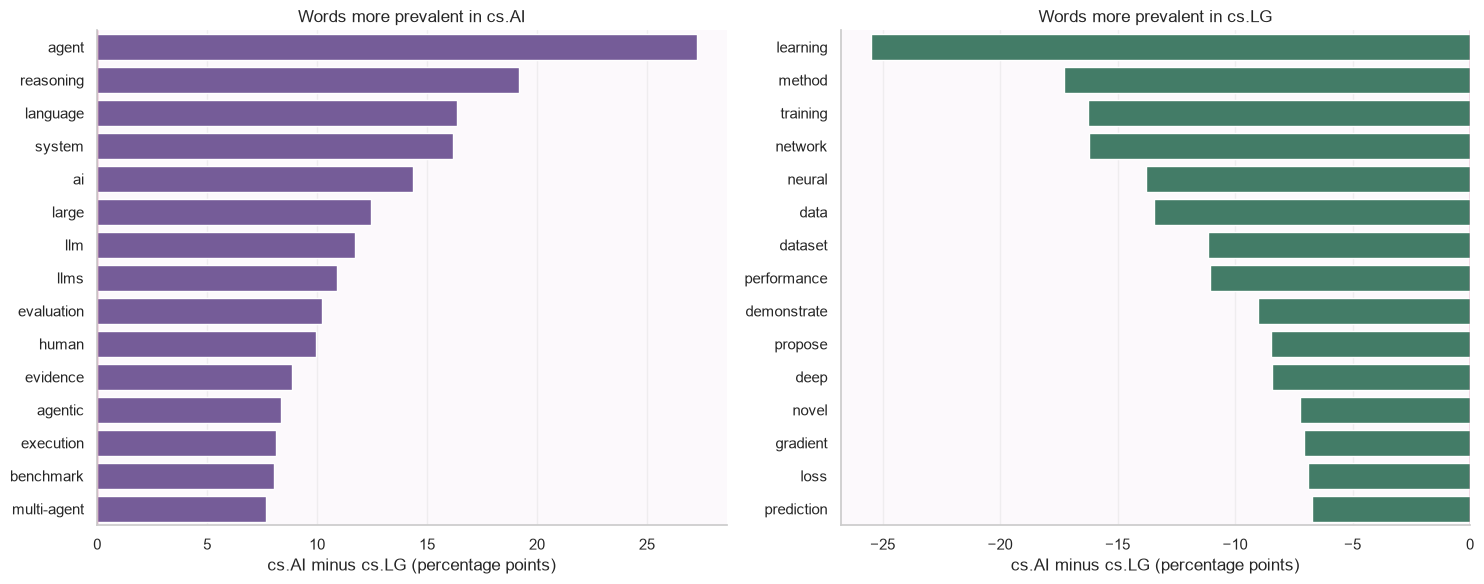

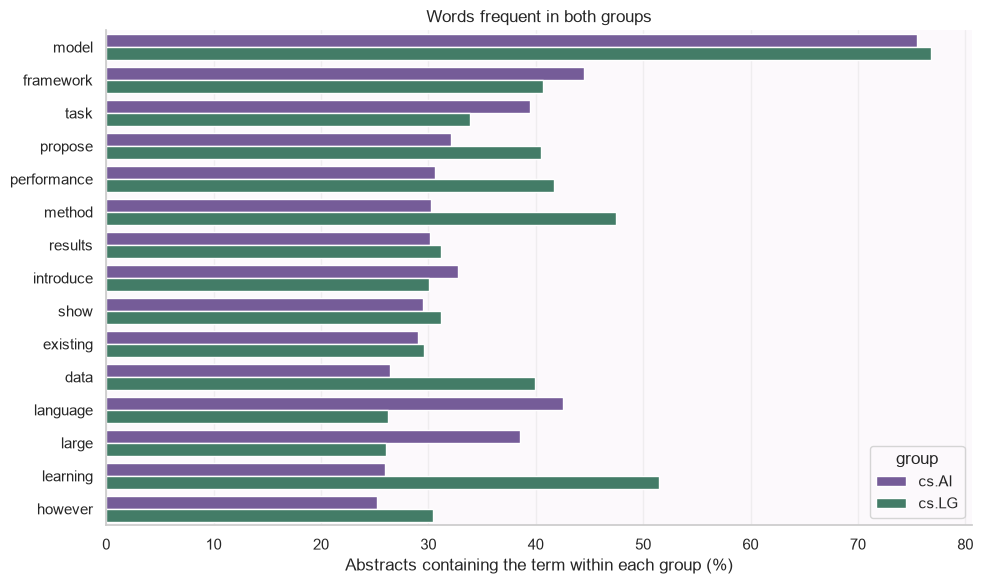

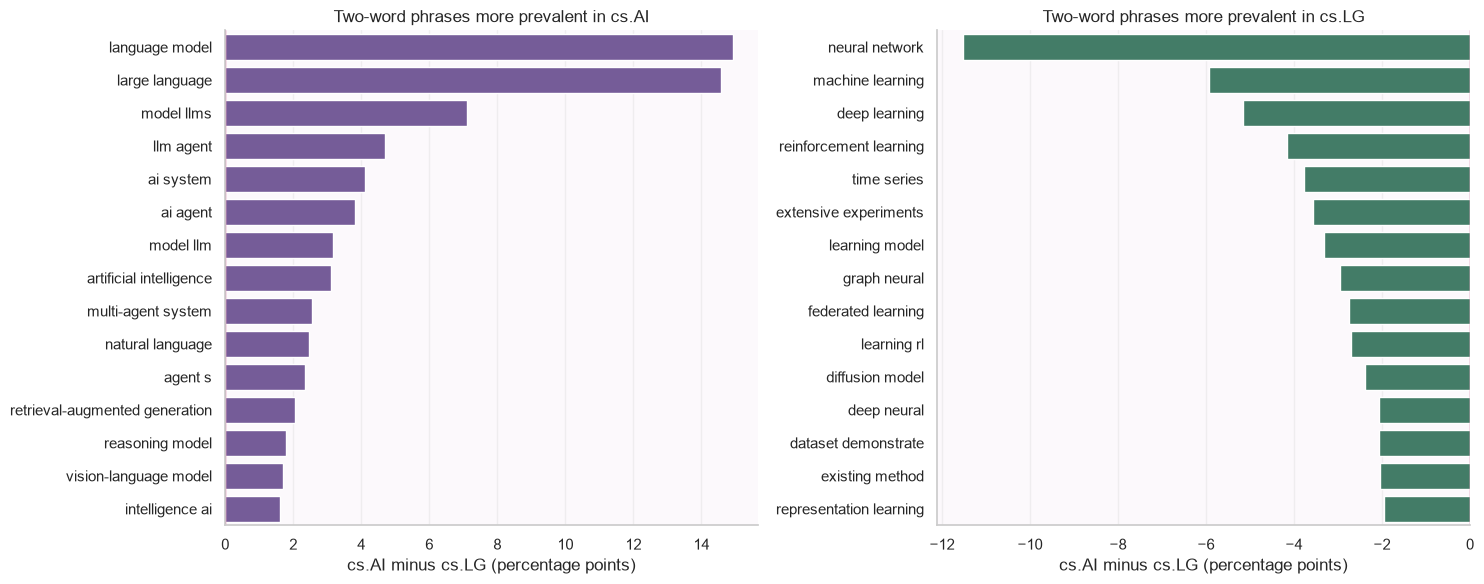

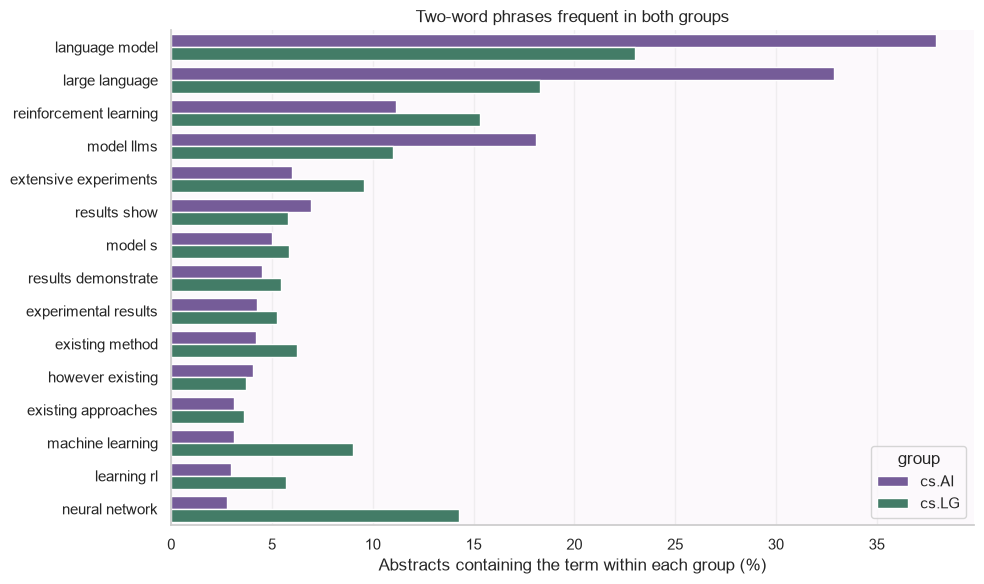

In [7]:
for kind in ["word", "two-word phrase"]:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for group, color, ax in [("cs.AI", PURPLE, axes[0]), ("cs.LG", GREEN, axes[1])]:
        table = rankings[kind][group]
        if table.empty:
            ax.text(0.5, 0.5, "No terms meet this ranking", ha="center", transform=ax.transAxes)
        else:
            sns.barplot(data=table, x="ai_minus_lg_pp", y="term", order=table["term"].tolist(), color=color, ax=ax)
            ax.axvline(0, color=PINK, linewidth=1)
        ax.set(title=f"{kind.capitalize()}s more prevalent in {group}", xlabel="cs.AI minus cs.LG (percentage points)", ylabel="")
    plt.tight_layout()
    plt.show()

    shared = rankings[kind]["shared"]
    if not shared.empty:
        long = shared.melt(id_vars="term", value_vars=["ai_pct", "lg_pct"], var_name="group", value_name="abstract_pct")
        long["group"] = long["group"].map({"ai_pct": "cs.AI", "lg_pct": "cs.LG"})
        fig, ax = plt.subplots(figsize=(10, 6))
        sns.barplot(data=long, x="abstract_pct", y="term", hue="group", order=shared["term"].tolist(), palette={"cs.AI": PURPLE, "cs.LG": GREEN}, ax=ax)
        ax.set(title=f"{kind.capitalize()}s frequent in both groups", xlabel="Abstracts containing the term within each group (%)", ylabel="")
        plt.tight_layout()
        plt.show()


### Term association plots with vertical jitter

For words and two-word phrases separately, select the union of the top `TOP_N` terms from the existing AI-associated, LG-associated, and shared rankings. Remove duplicate terms, so each plot shows at most `3 × TOP_N` words or phrases. No other terms or dots are drawn.

The exact X position remains **cs.AI minus cs.LG prevalence in percentage points**: LG-associated terms fall left, AI-associated terms fall right, and terms with similar prevalence fall near zero. Each plot has its own symmetric, linear X range based on its selected terms, retaining all selected outliers. Compare the numeric ticks, not visual distances between the two plots. Text uses blue → dark gray → red coloring centered at zero: blue for cs.LG and red for cs.AI. The shared, symmetric color range is based on the selected terms displayed across both plots, so the same percentage-point difference has the same color in both plots.

Assign Y positions from a **uniform distribution between −1 and 1**, with a fixed `LAYOUT_SEED` for reproducibility. The two-word phrase figure is taller (10 inches versus 6 for words) to give labels more vertical space. Extra vertical padding keeps labels away from the plot edges. The Y-axis is hidden: vertical position has no analytical meaning and does not represent semantic clusters or term similarity. Changing this seed changes only the layout, not the sampled papers, term statistics, or X positions.

A shared term can still have unequal prevalence and appear away from zero. Random placement does not guarantee no overlap; lower `TOP_N` or try a different layout seed if labels remain crowded.


In [ ]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from random import Random

LAYOUT_SEED = 42  # Changes label placement only, not the sampled papers or statistics.

association_cmap = LinearSegmentedColormap.from_list(
    "lg_shared_ai", ["#1565C0", "#424242", "#C62828"]
)
association_labels = {}
for kind in ["word", "two-word phrase"]:
    association_labels[kind] = pd.concat([
        rankings[kind][group].head(TOP_N)
        for group in ["cs.AI", "cs.LG", "shared"]
    ]).drop_duplicates("term").sort_values(["ai_minus_lg_pp", "term"])

color_limit = max(
    [float(labels["ai_minus_lg_pp"].abs().max())
     for labels in association_labels.values() if not labels.empty] + [0.1]
)
association_norm = Normalize(vmin=-color_limit, vmax=color_limit)

for kind, labels in association_labels.items():
    if labels.empty:
        print("No retained terms for:", kind)
        continue
    x_limit = max(float(labels["ai_minus_lg_pp"].abs().max()), 0.1)
    layout_rng = Random(LAYOUT_SEED)
    figure_height = 10 if kind == "two-word phrase" else 6
    fig, ax = plt.subplots(figsize=(16, figure_height))
    ax.axvline(0, color="dimgray", linestyle="--", linewidth=1, alpha=0.5)
    for row in labels.itertuples(index=False):
        ax.text(
            row.ai_minus_lg_pp, layout_rng.uniform(-1, 1), row.term,
            color=association_cmap(association_norm(row.ai_minus_lg_pp)),
            ha="center", va="center", fontsize=10,
        )
    ax.set(
        title=f"{kind.capitalize()}s: primary cs.LG ← similar prevalence → primary cs.AI",
        xlabel="cs.AI minus cs.LG abstract prevalence (percentage points)",
        xlim=(-x_limit * 1.15, x_limit * 1.15), ylim=(-1.2, 1.2),
    )
    ax.get_yaxis().set_visible(False)
    for spine in ["left", "right", "top"]:
        ax.spines[spine].set_visible(False)
    ax.grid(False)
    ax.grid(axis="x", alpha=0.15)
    fig.text(0.5, 0.01, "Vertical placement is uniform random jitter for readability; it has no analytical meaning.",
             ha="center", fontsize=9, color="dimgray")
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()


## 6. Read abstracts behind a term

Change `EXAMPLE_TERM` to a lowercase word or phrase from the tables and rerun the next cell. Matching uses the balanced sample and exactly the same plural/text rules as counting. The displayed term is normalized using PLURAL_MAP. Show up to three matching abstracts per group, earliest submissions first (not a random or representative sample). An empty result in one group is allowed.


In [9]:
EXAMPLE_TERM = "language model"
EXAMPLES_PER_GROUP = 3
EXAMPLE_TERM = " ".join(PLURAL_MAP.get(token, token) for token in TOKEN_PATTERN.findall(EXAMPLE_TERM.lower()))
print("Normalized example term:", EXAMPLE_TERM)

term_result = term_stats.loc[term_stats["term"].eq(EXAMPLE_TERM)]
if term_result.empty:
    print("This term is absent from the retained table, possibly because it is below MIN_DOCS.")
else:
    display(term_result[columns].round(2))

for group in GROUPS:
    examples = []
    candidates = papers.loc[papers["primary_category"].eq(group)].sort_values(["submitted", "arxiv_id"])
    for paper in candidates.itertuples(index=False):
        if EXAMPLE_TERM in abstract_terms(paper.abstract):
            examples.append({"arxiv_id": paper.arxiv_id, "submitted_at": paper.submitted_at,
                             "title": paper.title, "abstract": paper.abstract})
            if len(examples) >= EXAMPLES_PER_GROUP:
                break
    print(f"\nPrimary {group}: {len(examples)} example(s) for {EXAMPLE_TERM!r}")
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(examples))


Normalized example term: language model


,term,ai_docs,lg_docs,combined_docs,ai_pct,lg_pct,ai_minus_lg_pp
10285,language model,7435,4511,11946,37.93,23.01,14.92



Primary cs.AI: 3 example(s) for 'language model'


,arxiv_id,submitted_at,title,abstract
0,2501.00750v2,2025-01-01T06:36:56Z,Beyond Text: Implementing Multimodal Large Language Model-Powered Multi-Agent Systems Using a No-Code Platform,"This study proposes the design and implementation of a multimodal LLM-based Multi-Agent System (MAS) leveraging a No-Code platform to address the practical constraints and significant entry barriers associated with AI adoption in enterprises. Advanced AI technologies, such as Large Language Models (LLMs), often pose challenges due to their technical complexity and high implementation costs, making them difficult for many organizations to adopt. To overcome these limitations, this research develops a No-Code-based Multi-Agent System designed to enable users without programming knowledge to easily build and manage AI systems. The study examines various use cases to validate the applicability of AI in business processes, including code generation from image-based notes, Advanced RAG-based question-answering systems, text-based image generation, and video generation using images and prompts. These systems lower the barriers to AI adoption, empowering not only professional developers but also general users to harness AI for significantly improved productivity and efficiency. By demonstrating the scalability and accessibility of No-Code platforms, this study advances the democratization of AI technologies within enterprises and validates the practical applicability of Multi-Agent Systems, ultimately contributing to the widespread adoption of AI across various industries."
1,2501.01149v3,2025-01-02T09:03:56Z,A3: Android Agent Arena for Mobile GUI Agents with Essential-State Procedural Evaluation,"The advancement of Large Language Models (LLMs) and Multimodal Large Language Models (MLLMs) has catalyzed the development of mobile graphic user interface (GUI) AI agents, which is designed to autonomously perform tasks on mobile devices. However, a significant gap persists in mobile GUI agent evaluation, where existing benchmarks predominantly rely on either static frame assessments such as AndroidControl or offline static apps such as AndroidWorld and thus fail to capture agent performance in dynamic, real-world online mobile apps. To address this gap, we present Android Agent Arena (A3), a novel ""essential-state"" based procedural evaluation system for mobile GUI agents. A3 introduces a benchmark of 100 tasks derived from 20 widely-used, dynamic online apps across 20 categories from the Google Play Store, ensuring evaluation comprehension. A3 also presents a novel ""essential-state"" based procedural evaluation method that leverages MLLMs as reward models to progressively verify task completion and process achievement. This evaluation approach address the limitations of traditional function based evaluation methods on online dynamic apps. Furthermore, A3 includes a toolkit to streamline Android device interaction, reset online environment and apps and facilitate data collection from both human and agent demonstrations. The complete A3 system, including the benchmark and tools, will be publicly released to provide a robust foundation for future research and development in mobile GUI agents."
2,2501.01478v1,2025-01-02T12:09:17Z,Enhancing Reasoning through Process Supervision with Monte Carlo Tree Search,"Large language models (LLMs) have demonstrated their remarkable capacity across a variety of tasks. However, reasoning remains a challenge for LLMs. To improve LLMs' reasoning ability, process supervision has proven to be better than outcome supervision. In this work, we study using Monte Carlo Tree Search (MCTS) to generate process supervision data with LLMs themselves for training them. We sample reasoning steps with an LLM and assign each step a score that captures its ""relative correctness,"" and the LLM is then trained by minimizing weighted log-likelihood of generating the reasoning steps. This generate-then-train process is repeated iteratively unt


Primary cs.LG: 3 example(s) for 'language model'


,arxiv_id,submitted_at,title,abstract
0,2501.00692v1,2025-01-01T01:10:59Z,Adjoint sharding for very long context training of state space models,"Despite very fast progress, efficiently training large language models (LLMs) in very long contexts remains challenging. Existing methods fall back to training LLMs with short contexts (a maximum of a few thousands tokens in training) and use inference time techniques when evaluating on long contexts (above 1M tokens context window at inference). As opposed to long-context-inference, training on very long context input prompts is quickly limited by GPU memory availability and by the prohibitively long training times it requires on state-of-the-art hardware. Meanwhile, many real-life applications require not only inference but also training/fine-tuning with long context on specific tasks. Such applications include, for example, augmenting the context with various sources of raw reference information for fact extraction, fact summarization, or fact reconciliation tasks. We propose adjoint sharding, a novel technique that comprises sharding gradient calculation during training to reduce memory requirements by orders of magnitude, making training on very long context computationally tractable. Adjoint sharding is based on the adjoint method and computes equivalent gradients to backpropagation. We also propose truncated adjoint sharding to speed up the algorithm while maintaining performance. We provide a distributed version, and a paralleled version of adjoint sharding to further speed up training. Empirical results show the proposed adjoint sharding algorithm reduces memory usage by up to 3X with a 1.27B parameter large language model on 1M context length training. This allows to increase the maximum context length during training or fine-tuning of a 1.27B parameter model from 35K tokens to above 100K tokens on a training infrastructure composed of five AWS P4 instances."
1,2501.01793v1,2025-01-03T12:52:51Z,Creating Artificial Students that Never Existed: Leveraging Large Language Models and CTGANs for Synthetic Data Generation,"In this study, we explore the growing potential of AI and deep learning technologies, particularly Generative Adversarial Networks (GANs) and Large Language Models (LLMs), for generating synthetic tabular data. Access to quality students data is critical for advancing learning analytics, but privacy concerns and stricter data protection regulations worldwide limit their availability and usage. Synthetic data offers a promising alternative. We investigate whether synthetic data can be leveraged to create artificial students for serving learning analytics models. Using the popular GAN model CTGAN and three LLMs- GPT2, DistilGPT2, and DialoGPT, we generate synthetic tabular student data. Our results demonstrate the strong potential of these methods to produce high-quality synthetic datasets that resemble real students data. To validate our findings, we apply a comprehensive set of utility evaluation metrics to assess the statistical and predictive performance of the synthetic data and compare the different generator models used, specially the performance of LLMs. Our study aims to provide the learning analytics community with valuable insights into the use of synthetic data, laying the groundwork for expanding the field methodological toolbox with new innovative approaches for learning analytics data generation."
2,2501.03265v2,2025-01-04T06:17:48Z,Cognitive Edge Computing: A Comprehensive Survey on Optimizing Large Models and AI Agents for Pervasive Deployment,"This article surveys Cognitive Edge Computing as a practical and methodical pathway for deploying reasoning-capable Large Language Models (LLMs) and autonomous AI agents on resource-constrained devices at the network edge. We present a unified, cognition-preserving framework spanning: (1) model optimization (quantization, sparsity, low-rank adaptation, distillation) aimed at retaining multi-step reasoning un

## Review before choosing a next method

- Which differences look like subject matter, and which look like generic writing style or tokenization artifacts?
- Which terms are shared? Is the explicit plural mapping appropriate? Which unlisted forms or acronyms need researcher review?
- How does undersampling change the yearly composition? A fixed seed gives reproducibility, not evidence that rankings are stable across samples.
- Are selected abstracts methodological, application-focused, or mixed? Terms alone do not settle this.
- Could unequal time composition explain some differences? A subsequent comparison within shorter matched periods could investigate this.

Inspect examples before naming topics. These rankings do not explain the mid-2025 category-share change or establish a methodological shift. Agree on any text-rule changes, temporal comparison, embeddings, or clustering before implementation.
